# Fotony v pásmech Sentinelu-2B

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Švihadlo a fotony](https://openskylab.space/edu_viz_rope_and_photons.html) · [English version](rope_and_photons_en.ipynb)

Ve vizuálu jsi viděl, že u vlny na laně platí c = λ · f a že energii nese rozkmit i frekvence. U světla je to jinak: energii jednoho fotonu určuje jen frekvence, E = h · f, jas záření je počet fotonů. Tady to spočítáš pro skutečná pásma družice Sentinel-2B.

**Cíl:** z metadat skutečné scény Sentinel-2 spočítat frekvenci, energii fotonu a tok fotonů v každém pásmu a odvodit z nich, jaký detektor které pásmo potřebuje.

**Data:** metadata produktu Sentinel-2B L1C, dlaždice 33UVR (okolí Prahy), 21. 7. 2024 (`MTD_MSIL1C.xml` z veřejného archivu Google Cloud): střední vlnové délky, spektrální citlivost pásem a sluneční ozáření nad atmosférou. Stahuje se asi 50 kB.

**Úkoly:** šest. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 40 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a data

In [1]:
import re, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import h, c, e, k   # Planckova konstanta, rychlost světla, elementární náboj, Boltzmannova konstanta

# metadata jedné skutečné scény Sentinel-2B L1C (dlaždice 33UVR, 21. 7. 2024)
URL = ("https://storage.googleapis.com/gcp-public-data-sentinel-2/tiles/33/U/VR/"
       "S2B_MSIL1C_20240721T100559_N0510_R022_T33UVR_20240721T121133.SAFE/MTD_MSIL1C.xml")
xml = requests.get(URL, timeout=60).text
print(f"staženo {len(xml) / 1000:.0f} kB")

staženo 46 kB


In [2]:
# z XML vytáhneme pro každé pásmo: název, střední vlnovou délku, spektrální citlivost a sluneční ozáření E0
rows, srf = [], {}
for m in re.finditer(r'<Spectral_Information bandId="(\d+)" physicalBand="(\w+)">(.*?)</Spectral_Information>', xml, re.S):
    bid, name, body = int(m.group(1)), m.group(2), m.group(3)
    lmin = float(re.search(r'<MIN unit="nm">([\d.]+)', body).group(1))
    vals = np.array(re.search(r"<VALUES>(.*?)</VALUES>", body).group(1).split(), float)
    srf[name] = (lmin + np.arange(len(vals)), vals)          # krok 1 nm
    e0 = float(re.search(rf'<SOLAR_IRRADIANCE bandId="{bid}"[^>]*>([\d.]+)', xml).group(1))
    rows.append({"band": name,
                 "lambda_nm": float(re.search(r'<CENTRAL unit="nm">([\d.]+)', body).group(1)),
                 "E0_W_m2_um": e0})
bands = pd.DataFrame(rows).set_index("band")
bands

,lambda_nm,E0_W_m2_um
band,,
B1,442.3,1874.30
B2,492.3,1959.75
B3,559.0,1824.93
B4,665.0,1512.79
B5,703.8,1425.78
B6,739.1,1291.13
B7,779.7,1175.57
B8,833.0,1041.28
B8A,864.0,953.93


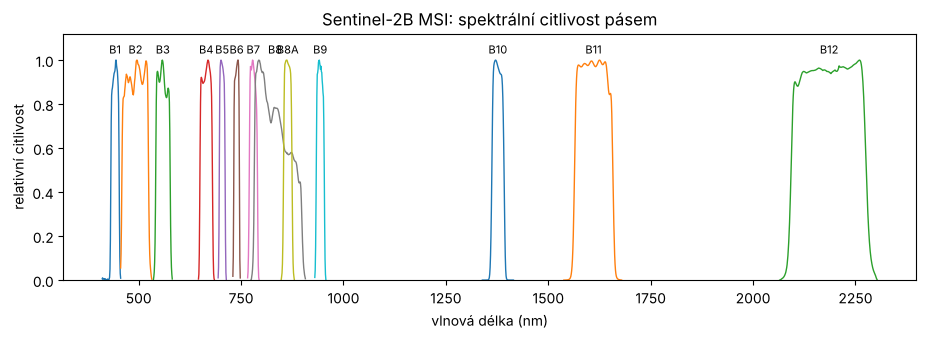

In [3]:
# spektrální citlivost pásem: jak silně detektor reaguje na jednotlivé vlnové délky
fig, ax = plt.subplots(figsize=(11, 3.2))
for name, (wl, r) in srf.items():
    ax.plot(wl, r, lw=1)
    ax.text(bands.lambda_nm[name], 1.03, name, ha="center", fontsize=8)
ax.set(xlabel="vlnová délka (nm)", ylabel="relativní citlivost", ylim=(0, 1.12), title="Sentinel-2B MSI: spektrální citlivost pásem")
plt.show()

## 2. Vlnová délka a frekvence

In [4]:
lam = bands.lambda_nm * 1e-9               # m
bands["f_THz"] = c / lam / 1e12            # f = c / λ
bands["lambda_x_f"] = lam * bands.f_THz * 1e12
bands[["lambda_nm", "f_THz", "lambda_x_f"]].round(1)

,lambda_nm,f_THz,lambda_x_f
band,,,
B1,442.3,677.8,299792458.0
B2,492.3,609.0,299792458.0
B3,559.0,536.3,299792458.0
B4,665.0,450.8,299792458.0
B5,703.8,426.0,299792458.0
B6,739.1,405.6,299792458.0
B7,779.7,384.5,299792458.0
B8,833.0,359.9,299792458.0
B8A,864.0,347.0,299792458.0


> **✏️ Úkol 1.** Sloupec `lambda_x_f` je u všech pásem stejný. Co vyjadřuje a čemu odpovídá na laně ve vizuálu? Kolikrát vyšší frekvenci má pásmo B2 (modrá) než B12 (SWIR 2)?

*Tvoje odpověď:* 

## 3. Energie jednoho fotonu

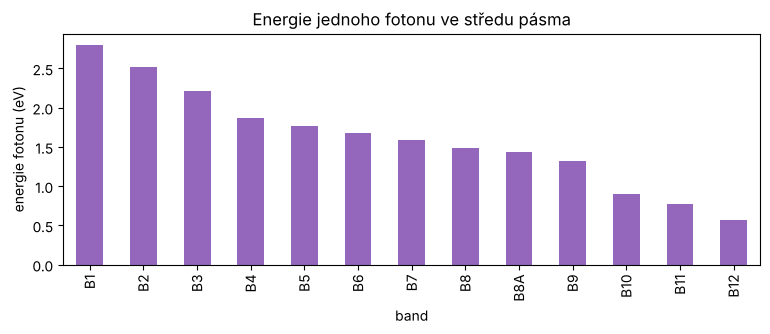

modrý (B2) / červený (B4) foton: 1.35 ×


In [5]:
bands["E_photon_eV"] = h * c / lam / e     # E = h·f = h·c/λ, převedeno na elektronvolty
ax = bands.E_photon_eV.plot.bar(figsize=(9, 3), color="tab:purple")
ax.set(ylabel="energie fotonu (eV)", title="Energie jednoho fotonu ve středu pásma")
plt.show()
print(f"modrý (B2) / červený (B4) foton: {bands.E_photon_eV['B2'] / bands.E_photon_eV['B4']:.2f} ×")

> **✏️ Úkol 2.** Ověř poměr energií modrého a červeného fotonu jen z vlnových délek, bez konstant. Proč stačí poměr λ? Jak se změní energie jednoho fotonu, když je modré světlo dvakrát jasnější?

*Tvoje odpověď:* 

## 4. Jas je počet fotonů

Metadata uvádějí pro každé pásmo sluneční ozáření nad atmosférou E0 ve W·m⁻²·µm⁻¹. Když ho vydělíme energií jednoho fotonu, dostaneme, kolik fotonů za sekundu dopadne na metr čtvereční v jednom mikrometru spektra.

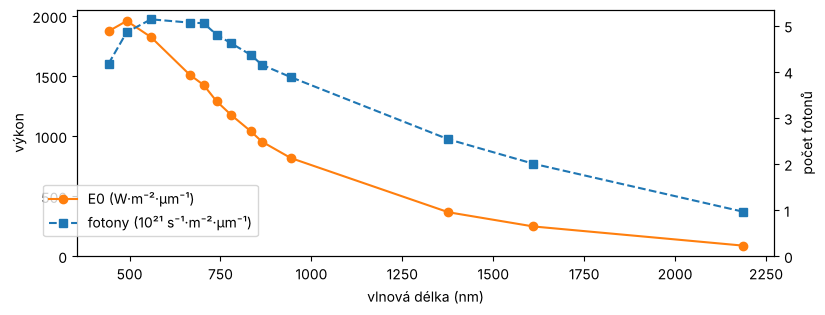

,E0_W_m2_um,E_photon_eV,photons_per_s_m2_um
band,,,
B1,1.87e+03,2.8,4.17e+21
B2,1.96e+03,2.52,4.86e+21
B3,1.82e+03,2.22,5.14e+21
B4,1.51e+03,1.86,5.06e+21
B5,1.43e+03,1.76,5.05e+21
B6,1.29e+03,1.68,4.8e+21
B7,1.18e+03,1.59,4.61e+21
B8,1.04e+03,1.49,4.37e+21
B8A,954,1.44,4.15e+21


In [6]:
bands["photons_per_s_m2_um"] = bands.E0_W_m2_um / (bands.E_photon_eV * e)
fig, ax1 = plt.subplots(figsize=(9, 3.2))
ax1.plot(bands.lambda_nm, bands.E0_W_m2_um, "o-", c="tab:orange", label="E0 (W·m⁻²·µm⁻¹)")
ax2 = ax1.twinx()
ax2.plot(bands.lambda_nm, bands.photons_per_s_m2_um / 1e21, "s--", c="tab:blue", label="fotony (10²¹ s⁻¹·m⁻²·µm⁻¹)")
ax1.set(xlabel="vlnová délka (nm)", ylabel="výkon"); ax2.set(ylabel="počet fotonů", ylim=(0, None)); ax1.set_ylim(0)
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.15)); plt.show()
bands[["E0_W_m2_um", "E_photon_eV", "photons_per_s_m2_um"]].style.format("{:.3g}")

> **✏️ Úkol 3.** Výkon E0 klesá od modré (B2) k SWIR 2 (B12) více než dvacetkrát. Klesá stejně i počet fotonů? Vysvětli rozdíl. V kterém pásmu dopadá na metr čtvereční nejvíc fotonů na mikrometr spektra a proč to není pásmo s nejvyšším E0?

*Tvoje odpověď:* 

## 5. Které pásmo uvidí křemíkový čip

Foton detektor uvolní elektron jen tehdy, když má aspoň energii zakázaného pásu materiálu. U křemíku je to asi 1,12 eV. Spočítáme mezní vlnovou délku a podíváme se, jak velká část citlivosti každého pásma leží pod ní.

In [7]:
Eg = 1.12          # ◀ parametr: šířka zakázaného pásu v eV (křemík 1,12; InGaAs asi 0,75; HgCdTe podle složení 0,1–0,5)
lam_cut = h * c / (Eg * e) * 1e9
print(f"mezní vlnová délka: {lam_cut:.0f} nm")
share = {name: r[wl <= lam_cut].sum() / r.sum() for name, (wl, r) in srf.items()}
bands["share_detectable"] = pd.Series(share)
bands[["lambda_nm", "E_photon_eV", "share_detectable"]].style.format({"lambda_nm": "{:.0f}", "E_photon_eV": "{:.2f}", "share_detectable": "{:.0%}"})

mezní vlnová délka: 1107 nm


,lambda_nm,E_photon_eV,share_detectable
band,,,
B1,442,2.80,100%
B2,492,2.52,100%
B3,559,2.22,100%
B4,665,1.86,100%
B5,704,1.76,100%
B6,739,1.68,100%
B7,780,1.59,100%
B8,833,1.49,100%
B8A,864,1.44,100%


> **✏️ Úkol 4.** Která pásma Sentinelu-2 by křemíkový detektor zachytil celá, která jen zčásti a která vůbec? Nastav `Eg = 0.75` (InGaAs) a spusť buňku znovu. Co se změnilo? Sentinel-2 má pro pásma B10 až B12 detektory z HgCdTe: proč?

*Tvoje odpověď:* 

## 6. Termální záření a radar

Porovnáme fotony z termálního pásma (10,9 µm, jako Landsat 8 TIRS) a z radaru Sentinel-1 (5,405 GHz) s typickou tepelnou energií kmitů v detektoru při pokojové teplotě, k · T.

In [8]:
T = 300            # ◀ parametr: teplota detektoru v kelvinech
kT = k * T / e
other = pd.DataFrame({
    "lambda_m": [h * c / (10 * e), 490e-9, 1610e-9, 10.9e-6, c / 5.405e9],
}, index=["ionizace (10 eV)", "B2 modrá", "B11 SWIR", "termální 10,9 µm", "radar C 5,405 GHz"])
other["E_eV"] = h * c / other.lambda_m / e
other["E_over_kT"] = other.E_eV / kT
print(f"k·T při {T} K = {kT * 1000:.1f} meV")
other.style.format({"lambda_m": "{:.3g}", "E_eV": "{:.3g}", "E_over_kT": "{:.3g}"})

k·T při 300 K = 25.9 meV


,lambda_m,E_eV,E_over_kT
ionizace (10 eV),1.24e-07,10,387
B2 modrá,4.9e-07,2.53,97.9
B11 SWIR,1.61e-06,0.77,29.8
"termální 10,9 µm",1.09e-05,0.114,4.4
"radar C 5,405 GHz",0.0555,2.24e-05,0.000865


> **✏️ Úkol 5.** Termální foton má energii jen asi čtyřikrát větší než k · T, radarový foton je víc než tisíckrát slabší než k · T. Proč proto termální kamery s fotonovými detektory chladí a proč mikrobolometr a radarová anténa neměří jednotlivé fotony, ale ohřev, resp. elektrické pole vlny? Nastav `T = 77` (kapalný dusík) a porovnej.

*Tvoje odpověď:* 

> **✏️ Úkol 6.** Na jaké vlnové délce má foton energii 10 eV (přibližná hranice ionizace)? Do které oblasti spektra patří? Chemické vazby v molekulách mají energii v řádu několika eV. Vysvětli, proč jediný foton UV záření může poškodit DNA, zatímco silný radarový signál nese celkem víc energie, a přesto žádnou vazbu nerozbije ani nic neionizuje.

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Spolužáci mohou mít notebook pro jinou družici řady Sentinel-2 (2A, 2B nebo 2C). Porovnejte střední vlnové délky pásem a hodnoty E0: o kolik nanometrů se pásma stejného jména liší a proč s tím musí počítat, kdo skládá časovou řadu ze snímků více družic?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Copernicus Sentinel-2 data 2024, ESA; metadata L1C z veřejného archivu Google Cloud (`gcp-public-data-sentinel-2`). Licence: [Legal notice on the use of Copernicus Sentinel Data](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice), volné užití s uvedením zdroje.
- Konstanty h, c, e, k: v SI od roku 2019 přesně definované hodnoty, převzaté z `scipy.constants`.
- Šířka zakázaného pásu křemíku 1,12 eV při 300 K: Sze, S. M., Ng, K. K. (2007). *Physics of Semiconductor Devices*, 3. vyd. Wiley.
- Frekvence radaru Sentinel-1 (pásmo C) 5,405 GHz: ESA, Sentinel-1 User Handbook.

### Jak citovat

OpenSkyLab (2026). Fotony v pásmech Sentinelu-2B [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*